# 00. Собственный генератор сигналов и датасет

**Цель этапа:** подготовить собственный размеченный датасет, в котором для каждого примера известны
не только вид модуляции, но и все параметры сигнала и канала (метки для регрессии, этап 4а),
а класс AM-SSB — настоящий однополосный сигнал (в RadioML 2016.10a он оказался шумом, см. 01_eda).

**Шаги:**
1. Устройство генератора.
2. Проверка: сигналы без искажений канала.
3. Проверка: что делает канал.
4. Проверка меток (автотесты + спектры z^M).
5. Сгенерированный датасет: распределения параметров, разбиение.
6. Сравнение с RadioML.
7. Выводы.

## 1. Устройство генератора (`src/amc/generator.py`)

| Блок | Что делается | Случайные параметры (метки) |
|---|---|---|
| Цифровые линейные (BPSK, QPSK, 8PSK, PAM4, QAM16, QAM64) | случайные символы × импульс RRC, вычисленный в моменты отсчётов (дробное число отсчётов на символ) | отсчётов на символ 4–16 (лог-равномерно), roll-off 0,2–0,5, задержка |
| ЧМн с непрерывной фазой (CPFSK, GFSK) | мгновенная частота = Σ символ × частотный импульс (прямоугольный / гауссов), фаза — интеграл | индекс h 0,4–1,0 (разнос = h·Rs), BT 0,3–0,5 |
| Аналоговые (AM-DSB, AM-SSB, WBFM) | модулирующий сигнал «речь» (окрашенный шум со слоговой огибающей) или «музыка» (тоны с гармониками), **без пауз** | полоса звука, глубина АМ 0,3–1, боковая USB/LSB, девиация ЧМ |
| Канал | многолучёвость 2–4 луча, задержки до 1,5 символа, замирания Рэлея/Райса с доплеровским рассеянием; фазовый шум; сдвиг частоты ±0,05·fs; ошибка частоты дискретизации ±100 ppm | все записаны в метаданные |
| Шум | AWGN, ОСШ −20…+20 дБ (непрерывно), во всей полосе fs — как в RadioML | snr_db |
| Нормировка | пример приводится к единичной мощности | — |

Воспроизводимость: каждый кусок датасета генерируется от `SeedSequence(seed, spawn_key=(номер куска,))` —
результат не зависит от числа процессов.

In [1]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from amc.generator import CLASSES, GenConfig, generate_one
from amc.radioml import load_npz

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures" / "generator"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
IDEAL = GenConfig(snr_db=(40.0, 40.0), p_multipath=0.0, phase_noise=(0.0, 0.0), sro_ppm=0.0, cfo=0.0)


def savefig(name: str) -> None:
    """Сохранить рисунок."""
    plt.savefig(FIG / f"{name}.png", dpi=120, bbox_inches="tight")


def psd_db(z: np.ndarray, nfft: int = 256) -> tuple[np.ndarray, np.ndarray]:
    """Усреднённый спектр мощности, дБ."""
    seg = z[: len(z) // nfft * nfft].reshape(-1, nfft) * np.hanning(nfft)
    p = np.mean(np.abs(np.fft.fftshift(np.fft.fft(seg, axis=1), axes=1)) ** 2, axis=0)
    return np.linspace(-0.5, 0.5, nfft, endpoint=False), 10 * np.log10(p / p.max() + 1e-12)

## 2. Сигналы без искажений канала (ОСШ 40 дБ, без сдвига частоты и многолучёвости)

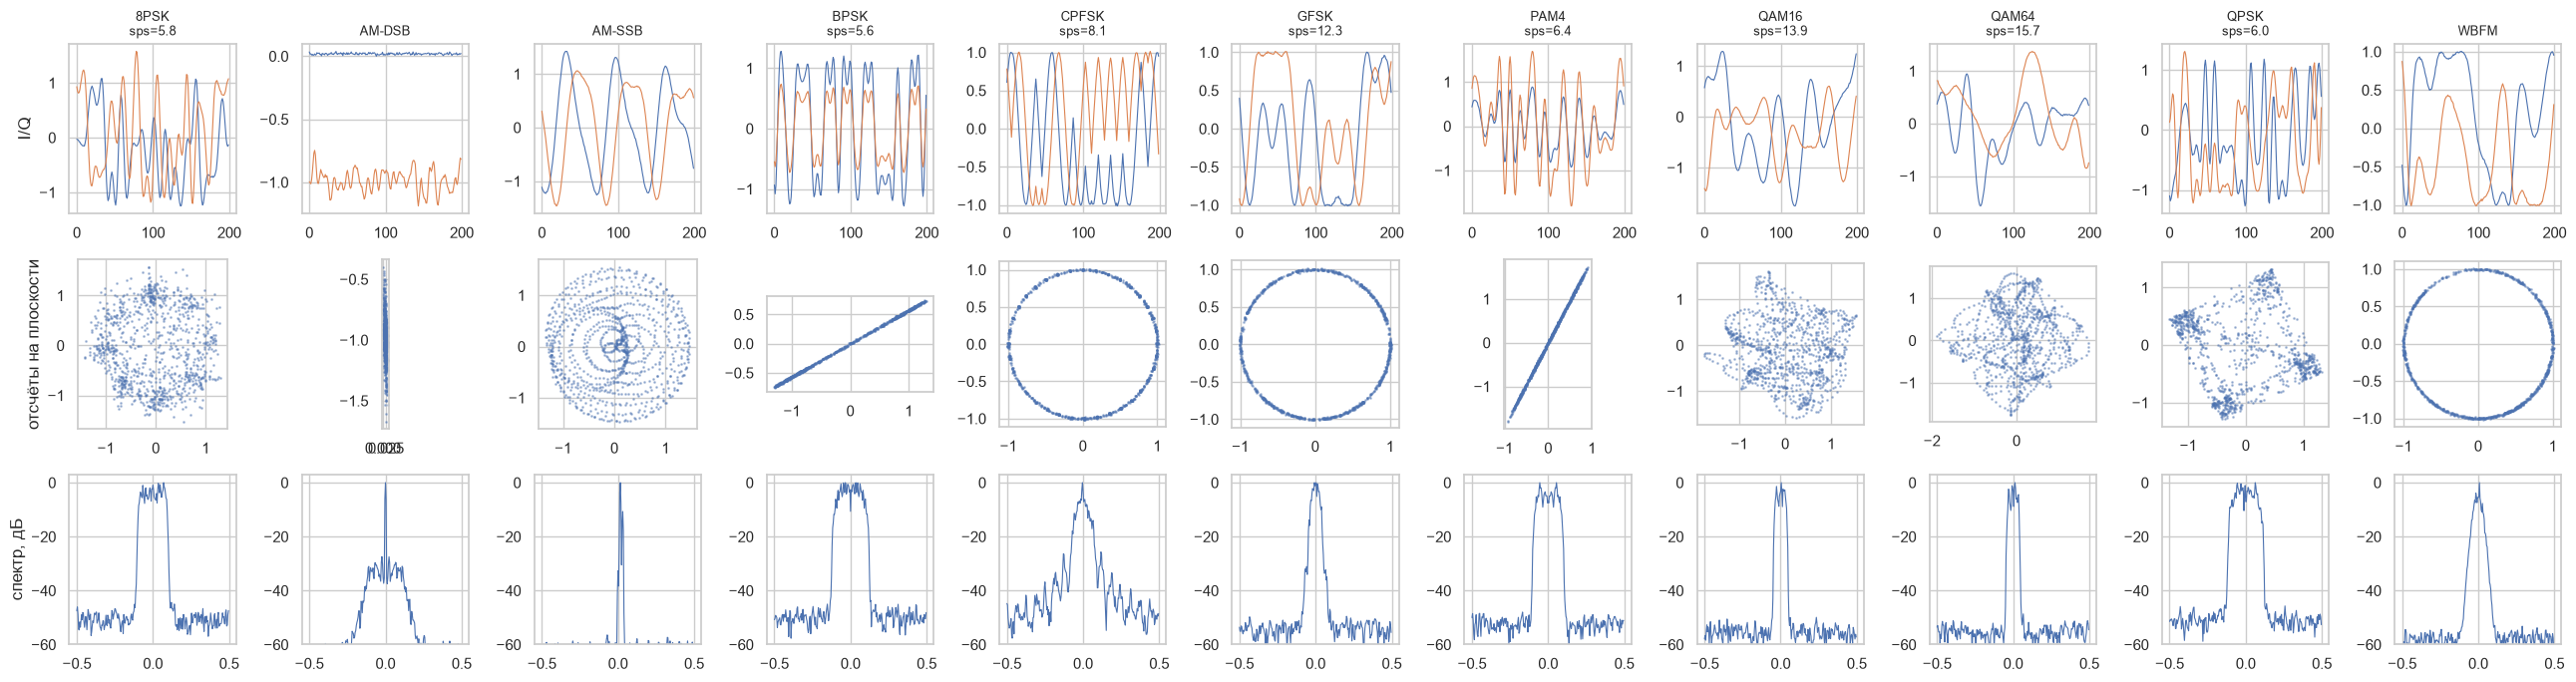

In [2]:
fig, axes = plt.subplots(3, 11, figsize=(26, 7))
for j, c in enumerate(CLASSES):
    z, m = generate_one(c, np.random.default_rng(j), IDEAL)
    axes[0, j].plot(z.real[:200], lw=0.8)
    axes[0, j].plot(z.imag[:200], lw=0.8)
    title = c if np.isnan(m["sps"]) else f"{c}\nsps={m['sps']:.1f}"
    axes[0, j].set_title(title, fontsize=9)
    axes[1, j].scatter(z.real, z.imag, s=1, alpha=0.4)
    axes[1, j].set_aspect("equal")
    f, p = psd_db(z)
    axes[2, j].plot(f, p, lw=0.8)
    axes[2, j].set_ylim(-60, 3)
axes[0, 0].set_ylabel("I/Q")
axes[1, 0].set_ylabel("отсчёты на плоскости")
axes[2, 0].set_ylabel("спектр, дБ")
plt.tight_layout()
savefig("clean_signals")
plt.show()

Огибающие и спектры соответствуют теории: у ЧМн и WBFM постоянная огибающая (кольцо), у АМ — несущая
плюс боковые полосы, у AM-SSB — **одна боковая полоса** (асимметричный спектр), у линейных модуляций —
спектр RRC шириной (1 + roll-off)/sps.

## 3. Что делает канал
Один и тот же QPSK-сигнал: без искажений → со сдвигом частоты и фазовым шумом → с многолучёвостью → с шумом 5 дБ.

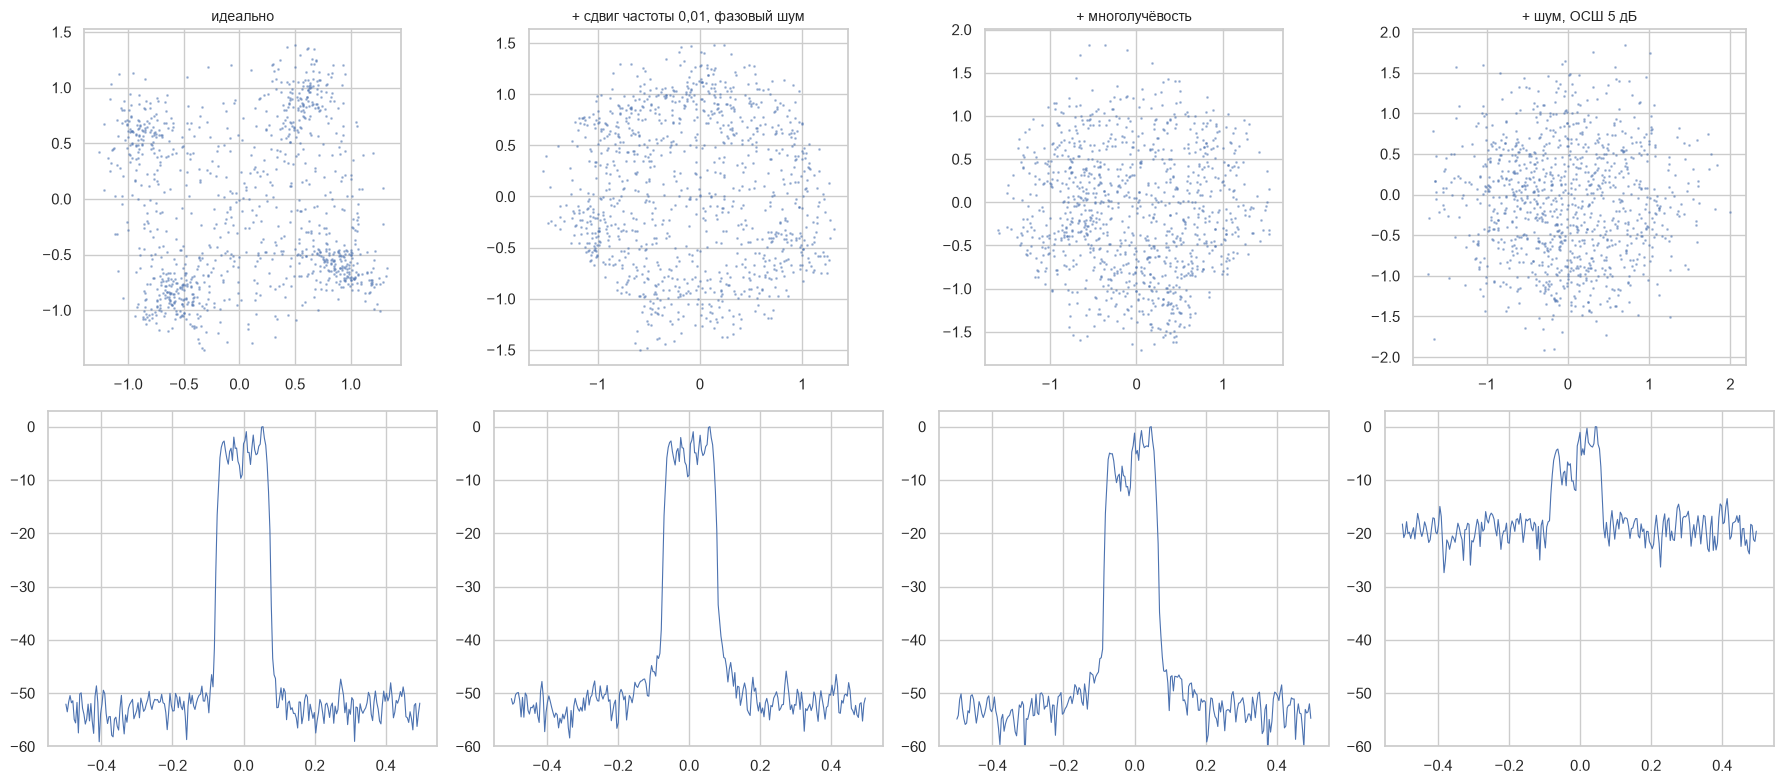

In [3]:
seed = 11
steps = {
    "идеально": IDEAL,
    "+ сдвиг частоты 0,01, фазовый шум": replace(IDEAL, cfo=0.01, phase_noise=(5e-5, 5e-5)),
    "+ многолучёвость": replace(IDEAL, cfo=0.01, phase_noise=(5e-5, 5e-5), p_multipath=1.0, p_rician=0.0),
    "+ шум, ОСШ 5 дБ": replace(IDEAL, cfo=0.01, phase_noise=(5e-5, 5e-5), p_multipath=1.0, p_rician=0.0,
                                  snr_db=(5.0, 5.0)),
}
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for j, (name, cfg) in enumerate(steps.items()):
    z, m = generate_one("QPSK", np.random.default_rng(seed), cfg)
    axes[0, j].scatter(z.real, z.imag, s=1, alpha=0.4)
    axes[0, j].set_aspect("equal")
    axes[0, j].set_title(name, fontsize=10)
    f, p = psd_db(z)
    axes[1, j].plot(f, p, lw=0.8)
    axes[1, j].set_ylim(-60, 3)
plt.tight_layout()
savefig("channel_steps")
plt.show()

## 4. Проверка меток

Автотесты `tests/test_generator.py` (31 тест, все проходят) проверяют, что метки соответствуют сигналу:
- измеренное ОСШ совпадает с меткой (±0,5 дБ);
- у QPSK пик спектра z⁴ — на частоте 4·cfo (±2·10⁻⁴);
- полоса 99 % линейных модуляций ≈ (1 + roll-off)/sps;
- у AM-SSB > 95 % мощности по одну сторону несущей (USB/LSB — как в метке);
- у CPFSK разнос тонов = h/sps (±15 %);
- одинаковый seed → одинаковый сигнал.

Наглядная проверка: спектр z^M «снимает» M-позиционную ФМн и даёт линию на частоте M·cfo —
это и есть будущий классический оценщик сдвига частоты (этап 4а).

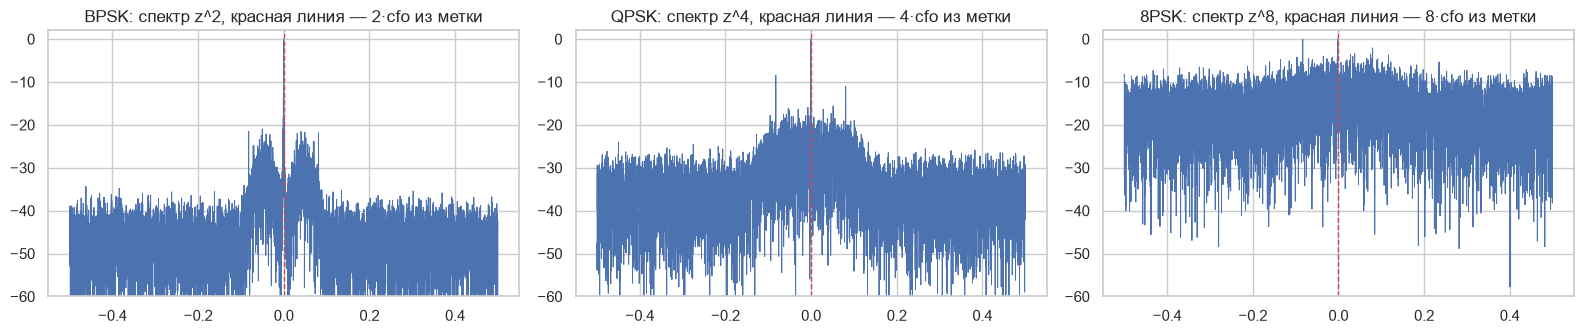

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, (c, M) in zip(axes, [("BPSK", 2), ("QPSK", 4), ("8PSK", 8)]):
    cfg = replace(IDEAL, cfo=0.01, snr_db=(15.0, 15.0), n=4096)
    z, m = generate_one(c, np.random.default_rng(5), cfg)
    s = np.abs(np.fft.fftshift(np.fft.fft(z.astype(complex) ** M, 1 << 14)))
    f = np.fft.fftshift(np.fft.fftfreq(1 << 14))
    ax.plot(f, 20 * np.log10(s / s.max()), lw=0.7)
    ax.axvline(M * m["cfo"], c="r", ls="--", lw=1)
    ax.set_title(f"{c}: спектр z^{M}, красная линия — {M}·cfo из метки")
    ax.set_ylim(-60, 2)
plt.tight_layout()
savefig("xm_lines")
plt.show()

## 5. Сгенерированный датасет `data/synth/v1`

In [5]:
D = ROOT / "data" / "synth" / "v1"
meta = pd.read_parquet(D / "meta.parquet")
X = np.load(D / "X.npy", mmap_mode="r")
print(X.shape, X.dtype, f"{X.nbytes / 2**30:.2f} ГиБ")
print(pd.crosstab(meta["cls"], meta["split"]))

(220000, 2, 1024) float32 1.68 ГиБ
split   test  train   val
cls                      
8PSK    3999  12000  4001
AM-DSB  4000  12000  4000
AM-SSB  3999  12000  4001
BPSK    3999  12000  4001
CPFSK   4001  12000  3999
GFSK    4001  11999  4000
PAM4    3998  12001  4001
QAM16   4000  12000  4000
QAM64   4001  11999  4000
QPSK    4000  11999  4001
WBFM    4000  12000  4000


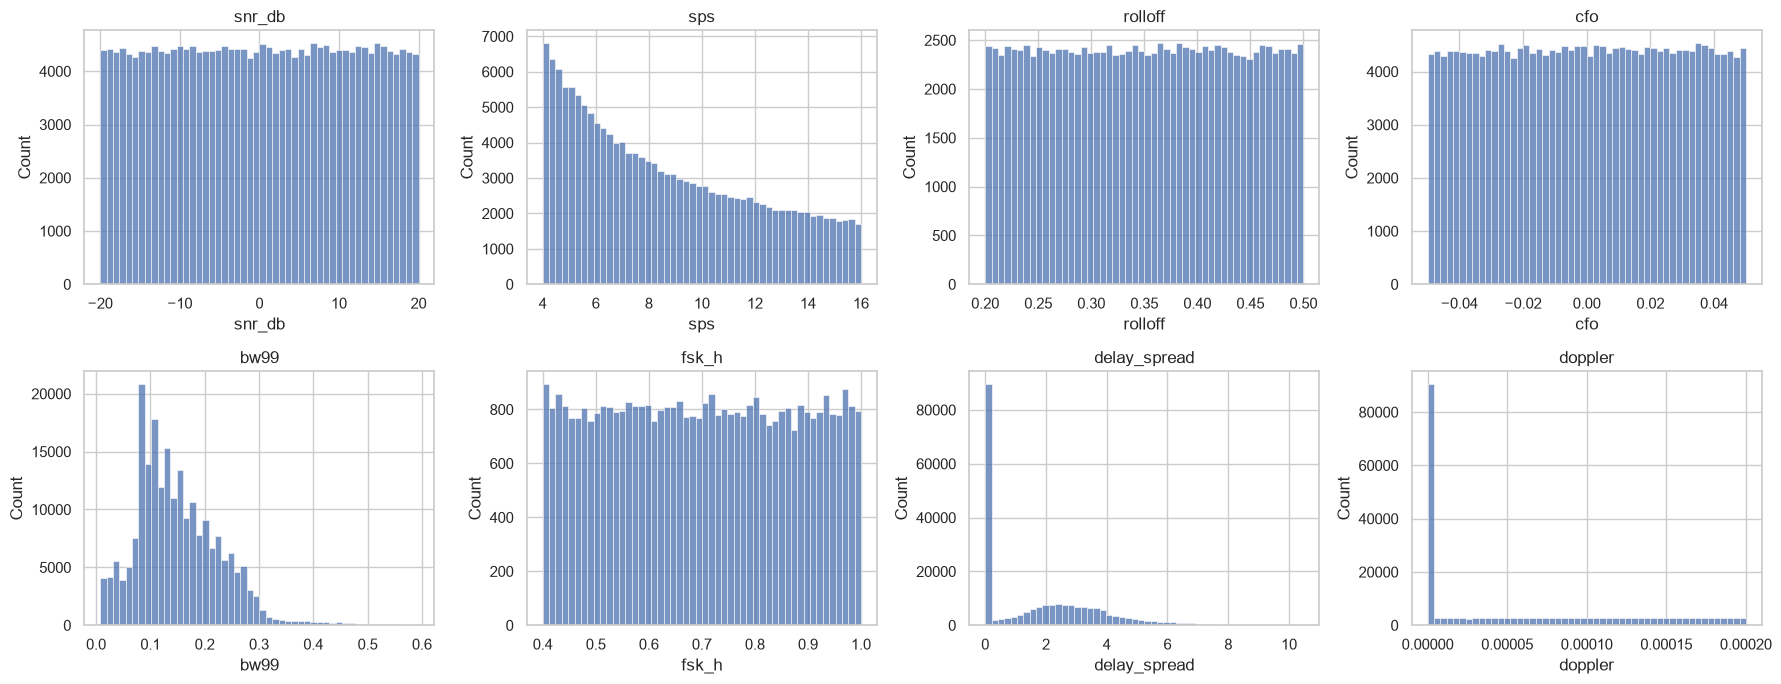

доля примеров с многолучёвостью: 0.6
cls
8PSK      0.145
AM-DSB    0.062
AM-SSB    0.059
BPSK      0.148
CPFSK     0.211
GFSK      0.141
PAM4      0.148
QAM16     0.148
QAM64     0.148
QPSK      0.148
WBFM      0.152
Name: bw99, dtype: float64


In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
cols = ["snr_db", "sps", "rolloff", "cfo", "bw99", "fsk_h", "delay_spread", "doppler"]
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(meta[col].dropna(), bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
savefig("param_hist")
plt.show()
print("доля примеров с многолучёвостью:", round(meta["multipath"].mean(), 3))
print(meta.groupby("cls")["bw99"].median().round(3))

## 6. Сравнение с RadioML 2016.10a (средние спектры при высоком ОСШ)

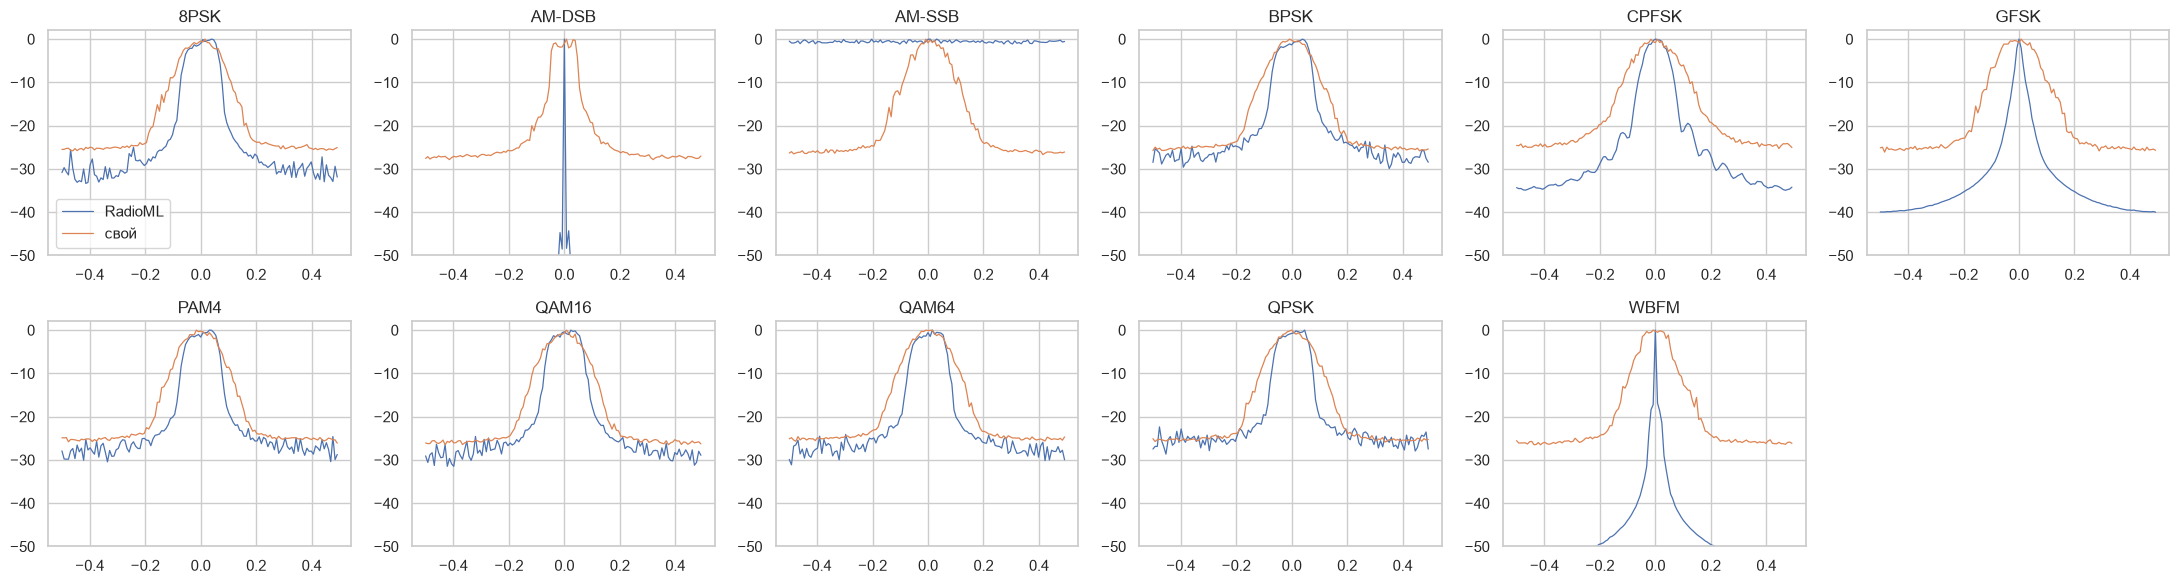

In [7]:
Xr, yr, sr, cr = load_npz(ROOT / "data" / "radioml" / "rml2016a.npz")
fig, axes = plt.subplots(2, 6, figsize=(22, 6))
for ax, c in zip(axes.ravel(), CLASSES):
    zr = Xr[(yr == cr.index(c)) & (sr == 18)][:300]
    zr = zr[:, 0] + 1j * zr[:, 1]
    pr = np.mean(np.abs(np.fft.fftshift(np.fft.fft(zr, axis=1), axes=1)) ** 2, axis=0)
    idx = np.flatnonzero((meta["cls"] == c).to_numpy() & (meta["snr_db"] > 15).to_numpy())[:300]
    zs = X[np.sort(idx), :, :128]
    zs = zs[:, 0] + 1j * zs[:, 1]
    ps = np.mean(np.abs(np.fft.fftshift(np.fft.fft(zs, axis=1), axes=1)) ** 2, axis=0)
    f = np.linspace(-0.5, 0.5, 128, endpoint=False)
    ax.plot(f, 10 * np.log10(pr / pr.max()), label="RadioML", lw=0.9)
    ax.plot(f, 10 * np.log10(ps / ps.max()), label="свой", lw=0.9)
    ax.set_title(c)
    ax.set_ylim(-50, 2)
axes[0, 0].legend()
axes.ravel()[-1].axis("off")
plt.tight_layout()
savefig("vs_radioml")
plt.show()

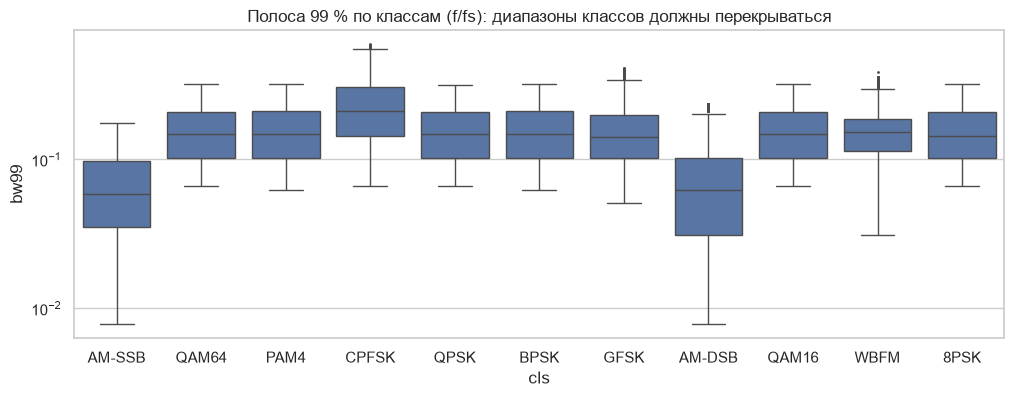

In [8]:
plt.figure(figsize=(12, 4))
sns.boxplot(data=meta, x="cls", y="bw99", fliersize=1)
plt.yscale("log")
plt.title("Полоса 99 % по классам (f/fs): диапазоны классов должны перекрываться")
savefig("bw_by_class")
plt.show()

**Отличия от RadioML (рисунок выше):**
- у RadioML GFSK и WBFM заметно уже: в RadioML WBFM — в основном несущая (паузы звука), GFSK — малый индекс;
  у нас индекс ЧМн 0,4–1,0 и звук без пауз;
- AM-SSB в RadioML — плоский шум, у нас — однополосный сигнал;
- полосы классов в своём датасете **перекрываются** (полоса звука 0,01–0,12 fs против 0,075–0,375 fs у цифровых):
  в первой версии генератора аналоговые сигналы были всегда уже цифровых, и модель могла бы различать классы
  по ширине полосы, а не по виду модуляции (обходной признак) — диапазон расширен, датасет пересоздан.

## 7. Выводы

- Собственный генератор воспроизводит те же 11 классов, что RadioML, и при этом даёт **полный набор меток
  параметров** (ОСШ, сдвиг частоты, символьная скорость, roll-off, полоса 99 %, индекс ЧМн, параметры канала)
  — именно это нужно для регрессии параметров (этап 4а).
- Корректность меток подтверждена автотестами и спектрами z^M.
- Исправлены дефекты RadioML: AM-SSB — настоящий однополосный сигнал; в аналоговых сигналах нет пауз.
- Свой датасет шире по условиям, чем RadioML: дробное и переменное число отсчётов на символ (4–16 против
  фиксированного ≈8), сдвиг частоты до ±0,05·fs, замирания — поэтому модели, обученные на RadioML,
  на нём, скорее всего, будут работать хуже. Это будет проверено в кросс-датасетном тесте (этап 5).
- Разбиение train/val/test 60/20/20 стратифицировано по (класс × интервал ОСШ 4 дБ).